In [1]:
from anemone.experiment import *
from anemone.forwards import *
from anemone.inversion import *
import matplotlib.pyplot as plt

In [2]:
tx = Loop.square(3)
rx = Receiver(x=13)
waveform = Waveform.example()
recfilter = FilterChain([ButterworthFilter(2.4e5,1),
                         ButterworthFilter(6.2e5,1),
                         ButterworthFilter(4.5e5,1)])

In [3]:
times = torch.logspace(-5,-3, 32)
fwrTD = ForwardLaplace6(tx, rx,times,filterfunc=recfilter, waveform=waveform)

c:\users\au653994\onedrive - aarhus universitet\documents\phd\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [4]:
def compute_relstd(t_gates, dbdt, noise_slope_exponent=-0.5, noise_level_at_1ms=1e-8, current=1., relative_noise=0.03):
    b = noise_level_at_1ms/(1e-3**noise_slope_exponent)
    abs_noise = b*(t_gates**noise_slope_exponent)
    y = dbdt*current
    std_rel = abs_noise/y
    relstd_tot = torch.sqrt(std_rel**2 + relative_noise**2)
    return relstd_tot

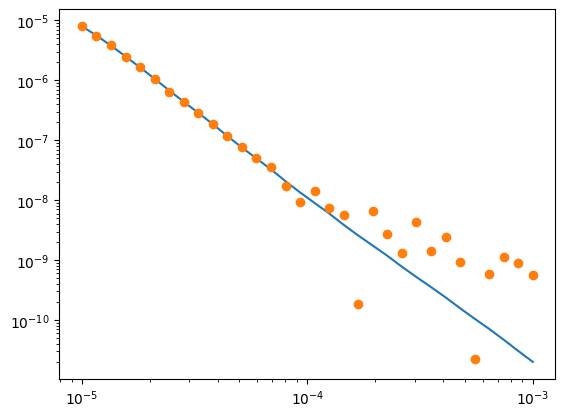

In [5]:
rho = torch.tensor([20, 80, 40])
thk = torch.tensor([20,20.])
mod_true = LogResistivity.few_layers(rho, thk)


dbdt_true = fwrTD(rho, thk)
d_relerr = compute_relstd(fwrTD.times, dbdt_true, current=10.)

d_obs = torch.abs(dbdt_true + dbdt_true * torch.randn_like(dbdt_true) * d_relerr)

plt.figure()
plt.loglog(fwrTD.times, dbdt_true, '-', label='Observed')
plt.loglog(fwrTD.times, d_obs, 'o', label='Observed')

In [6]:
res_start = LogResistivity.smooth(torch.ones(31)*50, torch.cumsum(torch.logspace(0,1,30), 0))
inv = Inversion(d_obs, d_relerr*dbdt_true, res_start, fwrTD)
inv.vertical_smoothness = 1.
res_mod = inv.invert()

array([<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>,
       <Axes: >], dtype=object)

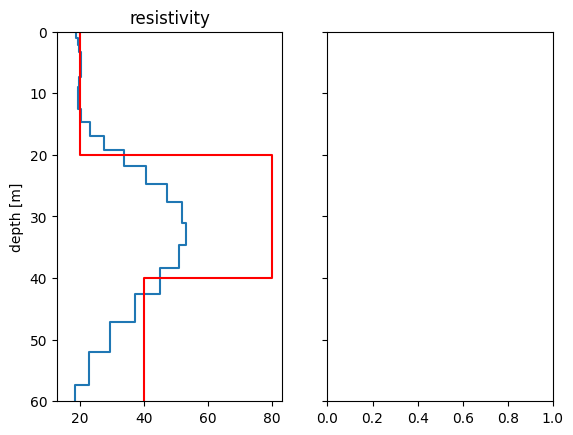

In [8]:
ax = res_mod.plot()
mod_true.plot(axs=ax, color='red', label='True model')


C:\Users\au653994\AppData\Local\Temp\ipykernel_17868\2804049733.py:31: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('rainbow')


array([<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>,
       <Axes: title={'center': 'phi'}>, <Axes: title={'center': 'tau'}>,
       <Axes: title={'center': 'c'}>], dtype=object)

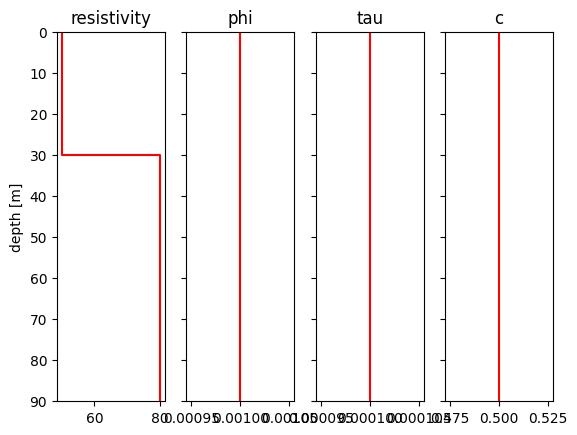

In [24]:
# Experiment to test the performance of different IP forward models from MPA and Cole  

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import torch
import pandas as pd

second_layer_rhos = torch.tensor([500, 100, 50, 10], dtype=torch.double)

thickness = torch.tensor([30], dtype=torch.double)
rho = torch.tensor([50, 1000], dtype=torch.double)
# Ip values for the MPA model in the second layer
phi_max_values = torch.logspace(start=torch.log10(torch.tensor(1)), 
                            end=torch.log10(torch.tensor(1000.0)), 
                            steps=10, dtype=torch.double)/1e3

tau_phi_values = torch.logspace(start=torch.log10(torch.tensor(1e-5)),
                            end=torch.log10(torch.tensor(1e-2)), 
                            steps=10, dtype=torch.double)

c_values = torch.tensor([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], dtype=torch.double)

phi_2 = torch.tensor(0.001, dtype=torch.double)
tau_phi_2 = 1e-4
c_2 = 0.5


# Colormap
cmap = cm.get_cmap('rainbow')
norm = mcolors.Normalize(vmin=float(c_values.min()), vmax=float(c_values.max()))
sm = cm.ScalarMappable(cmap=cmap, norm=norm)

mpa_true = LogMPA.few_layers([
    torch.tensor([50., 80.]),
    torch.tensor([0.001, 0.001]),
    torch.tensor([1e-4, 1e-4]),
    torch.tensor([0.5, 0.5])
],  torch.tensor([30, 30]))

mpa2 = LogMPA.few_layers([
    torch.tensor([50., 80., 80.]),
    torch.tensor([0.001, 0.001, 0.001]),
    torch.tensor([1e-4, 1e-4, 1e-4]),
    torch.tensor([0.5, 0.5, 0.5])
],  torch.tensor([30, 30]))


mpa2.plot(label='MPA2 True Model', color='red')



In [25]:
fwrmpa = ForwardLaplace6.mpa(tx, rx, fwrTD.times, waveform=waveform, filterfunc=recfilter)

c:\users\au653994\onedrive - aarhus universitet\documents\phd\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [26]:
mpa2.mod

[tensor([50.0000, 80.0000, 80.0000]),
 tensor([0.0010, 0.0010, 0.0010]),
 tensor([1.0000e-04, 1.0000e-04, 1.0000e-04]),
 tensor([0.5000, 0.5000, 0.5000]),
 tensor([30.0000, 30.0000])]

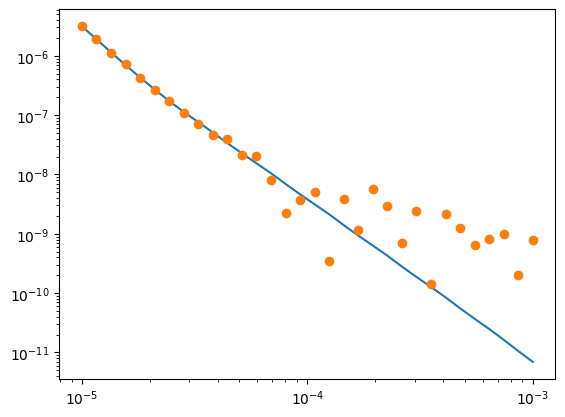

In [27]:
dbdt_true = fwrmpa(*mpa2.mod)
d_relerr = compute_relstd(fwrTD.times, dbdt_true, current=10.)
d_obs = torch.abs(dbdt_true + dbdt_true * torch.randn_like(dbdt_true) * d_relerr)


plt.figure()
plt.loglog(fwrmpa.times, dbdt_true, '-', label='Observed')
plt.loglog(fwrmpa.times, d_obs, 'o', label='Observed')


In [33]:
res_start = LogMPA.smooth([torch.ones(31)*10,
                           torch.ones(31)*0.005,
                           torch.ones(31)*5e-4,
                           torch.ones(31)*0.25
                           ], torch.cumsum(torch.logspace(0,1,30), 0))
inv = Inversion(d_obs, d_relerr*dbdt_true, res_start, fwrmpa)
inv.vertical_smoothness = 1.
inv.data_misfit_acceptance_threshold = 0.9
res_mpa = inv.invert()

001	misfit:	45.44
002	misfit:	16.57
003	misfit:	4.51
004	misfit:	1.58
005	misfit:	0.96
006	misfit:	0.82

6


array([<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>,
       <Axes: title={'center': 'phi'}>, <Axes: title={'center': 'tau'}>,
       <Axes: title={'center': 'c'}>, <Axes: >], dtype=object)

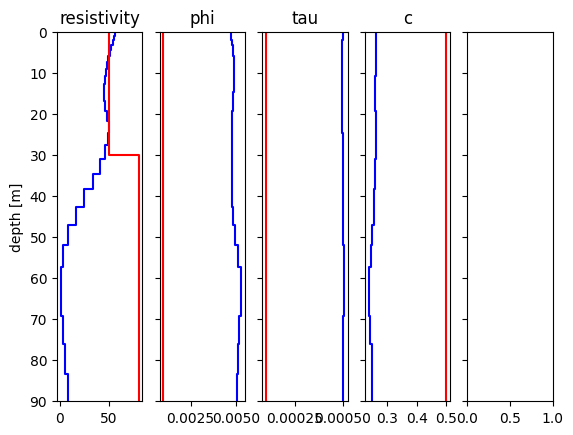

In [32]:
axs = res_mpa.plot(label='MPA Inversion Result', color='blue')
mpa2.plot(axs=axs, color='red', label='True MPA Model')